# Detector binário de Aedes: relatório final da adaptação — 01/10/2026

**Ainda não confiável: não atingiu os mínimos definidos antes do novo teste.** O modelo escolhido antes do teste foi **pcen_embedding_logistic**. Precisão no novo teste: **17.5%**; sensibilidade: **2.8%**; F1 Aedes: **4.8%**; macro-F1: **37.6%**. Acurácia geral: 54.7%. A decisão não usa apenas a última métrica.

## Acurácia não basta para dizer “confiável”

Foi considerado o [artigo indicado pelo usuário](https://www.dio.me/articles/por-que-a-acuracia-accuracy-nao-e-a-melhor-metrica-para-avaliar-o-desempenho-de-classificadores): uma maioria de negativos pode esconder falhas graves na detecção. Precisão mede quantos alertas Aedes estão corretos; sensibilidade mede quantos Aedes são encontrados. F1 equilibra os dois; macro-F1 e especificidade incluem a classe negativa. As definições foram verificadas na [documentação oficial do Google](https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall).

Registramos antes do teste: precisão, sensibilidade, macro-F1 e especificidade de pelo menos 60% no conjunto completo, entre apenas mosquitos e no domínio D3 com positivos e negativos; limites inferiores de 95% também de pelo menos 60% nessas métricas; sensibilidade Aedes e especificidade de cada táxon negativo de pelo menos 60%. São mínimos experimentais, não certificação. Inválidos não contam como acertos; desconhecidos não viram negativos.

A precisão depende da proporção de Aedes na amostra. Cenários de prevalência não são uma medição em campo. O artigo também inverte o efeito do limiar na sua explicação final: aumentar o limiar não aumenta a sensibilidade para scores fixos. Melhorar o modelo pode aumentar precisão e sensibilidade juntas.

## O que foi executado

As rodadas anteriores, incluindo reproduções de Fernandes e MosquitoSong+, redes residuais, misturas de treinamento e ensembles, estão documentadas no [relatório ampliado](reports/confiabilidade_binaria_aedes_2026_10_01.md). A rodada anterior adquiriu 670 gravações para treino/validação/calibração e treinou quatro redes, de até 9,65 milhões de parâmetros, mais três modelos clássicos. Todos foram congelados antes de baixar 182 arquivos adicionais para teste. A rede PCEN escolhida pela validação teve apenas 2,7% de sensibilidade nesse teste; foi reprovada.

Depois dessa reprovação, esta nova rodada:

- Incorporou **987 janelas de três gravações de fêmeas de outras espécies** antes usadas na validação MosquitoSong. Elas agora são **treino**, nunca validação independente. O treino passou para 25.495 janelas válidas e rotuladas; o corpus total mantém 49.713 janelas, incluindo as partições reservadas e exemplos desconhecidos.
- Reajustou ExtraTrees regularizado, ExtraTrees sem limite de profundidade e HistGradientBoosting com os novos negativos.
- Extraiu representações de 768 dimensões do encoder PCEN de 9,58 milhões de parâmetros, preservando seus pesos, e treinou duas cabeças logísticas com essas representações e as 138 features acústicas. A normalização foi ajustada apenas no treino. Esse classificador continua usando a rede grande na inferência; não é um modelo preparado para Arduino.
- Corrigiu a comparação de candidatos: a validação agora usa **o limiar final calibrado de cada candidato**, em vez de comparar todos por score bruto 0,5. Isso é uma melhoria da seleção, não a correção de um vazamento do teste.
- Manteve o áudio privado e todos os Aedes CD-MSC/UFRGS fora do treino. Não houve seleção, calibração ou filtro guiado pelo novo teste.

As representações neurais foram extraídas sem reajustar o encoder. A escolha do checkpoint original usou a validação da rodada anterior; os resultados dessa validação já são parte do desenvolvimento. Após a adaptação, não restam fêmeas negativas MosquitoSong independentes na validação; esta passa a usar Dryad, HumBug e ESC-50. Portanto, as métricas de validação anteriores e atuais não são comparações na mesma amostra.

Pré-processamento: mono, reamostragem, remoção de DC, normalização de RMS, PCEN/log-Mel/contraste e features bioacústicas. Áudio real de 0,3 ou 0,992 s, sem repetição ou extensão da onda. Ruídos e misturas artificiais usados em rodadas anteriores eram apenas aumentos de treino, nunca novos indivíduos ou enxames reais.


In [1]:
from pathlib import Path
import json,pandas as pd,numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
ROOT=Path.cwd()
if not (ROOT/'results/sex_balanced_reliability_2026_10_01').exists(): ROOT=ROOT.parent
O=ROOT/'results/sex_balanced_reliability_2026_10_01'
decision=json.loads((O/'reliability_decision.json').read_text())
selected=decision['selected_model']
metrics=pd.read_csv(O/'fresh_metrics.csv')
display(decision)

{'completed_utc': '2026-10-01T22:36:25.442420+00:00',
 'selected_model': 'pcen_embedding_logistic',
 'offline_minimum_criteria_passed': False,
 'failure_reasons': ['all_fresh: aedes_precision below .60',
  'all_fresh: aedes_precision lower95 below .60',
  'all_fresh: aedes_recall below .60',
  'all_fresh: aedes_recall lower95 below .60',
  'all_fresh: macro_f1 below .60',
  'all_fresh: macro_f1 lower95 below .60',
  'mosquito_only: aedes_precision below .60',
  'mosquito_only: aedes_precision lower95 below .60',
  'mosquito_only: aedes_recall below .60',
  'mosquito_only: aedes_recall lower95 below .60',
  'mosquito_only: macro_f1 below .60',
  'mosquito_only: macro_f1 lower95 below .60',
  'CDMSC2026_D3: aedes_precision lower95 below .60',
  'CDMSC2026_D3: aedes_recall below .60',
  'CDMSC2026_D3: aedes_recall lower95 below .60',
  'CDMSC2026_D3: macro_f1 below .60',
  'CDMSC2026_D3: macro_f1 lower95 below .60',
  'taxon:Aedes aegypti: aedes_recall below .60',
  'taxon:Anopheles funes

## Comparação e matriz de confusão: o modelo escolhido na validação permanece identificado

,name,validation_precision,validation_recall,validation_macro_f1,validation_minimum_recall,cut
0,trees_regularized_female,0.257092,0.601660,0.656039,0.572523,0.676449
1,trees_deep_female,0.252459,0.639004,0.655459,0.619825,0.656900
2,hist_boost_female,0.358396,0.593361,0.707133,0.558333,0.783032
3,pcen_embedding_logistic,0.412888,0.717842,0.747632,0.675000,0.778904


,model,selected,known_windows,aedes_precision,aedes_recall,aedes_f1,macro_f1,specificity,accuracy
0,hist_boost_female,False,1843,0.346154,0.048193,0.084606,0.402883,0.929745,0.572436
21,pcen_embedding_logistic,True,1843,0.175000,0.028112,0.048443,0.375823,0.901460,0.547477
42,pcen_large,False,1843,0.158537,0.052209,0.078550,0.367144,0.802920,0.498644
63,previous_round3_extra_trees_regularized,False,1843,0.373975,0.488621,0.423680,0.455443,0.434307,0.456321
84,trees_deep_female,False,1843,0.371859,0.099063,0.156448,0.430476,0.877737,0.562127
105,trees_regularized_female,False,1843,0.358696,0.088353,0.141783,0.423768,0.884124,0.561584


,model,selected,scope,groups,known_windows,unknown_windows,invalid,confusion_rows,confusion_columns,confusion,...,non_aedes_f1,macro_f1,balanced_accuracy,emitted_false_positive_rate,coverage,accuracy,roc_auc,average_precision,mcc_on_valid_audio,threshold
27,pcen_embedding_logistic,True,taxon:Aedes aegypti,24,747,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[0, 0, 0], [726, 21, 0]]",...,NaN,NaN,NaN,NaN,1.000000,0.028112,NaN,NaN,NaN,0.778904
28,pcen_embedding_logistic,True,taxon:Aedes albopictus,6,178,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[177, 1, 0], [0, 0, 0]]",...,0.997183,NaN,NaN,0.005618,1.000000,0.994382,NaN,NaN,NaN,0.778904
29,pcen_embedding_logistic,True,taxon:Anopheles arabiensis,3,6,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[4, 2, 0], [0, 0, 0]]",...,0.800000,NaN,NaN,0.333333,1.000000,0.666667,NaN,NaN,NaN,0.778904
30,pcen_embedding_logistic,True,taxon:Anopheles coustani,3,51,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[49, 2, 0], [0, 0, 0]]",...,0.980000,NaN,NaN,0.039216,1.000000,0.960784,NaN,NaN,NaN,0.778904
31,pcen_embedding_logistic,True,taxon:Anopheles funestus sl,3,50,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[49, 1, 0], [0, 0, 0]]",...,0.989899,NaN,NaN,0.020000,1.000000,0.980000,NaN,NaN,NaN,0.778904
32,pcen_embedding_logistic,True,taxon:Anopheles funestus ss,3,68,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[27, 41, 0], [0, 0, 0]]",...,0.568421,NaN,NaN,0.602941,1.000000,0.397059,NaN,NaN,NaN,0.778904
33,pcen_embedding_logistic,True,taxon:Anopheles harrisoni,2,8,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[8, 0, 0], [0, 0, 0]]",...,1.000000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN,NaN,0.778904
34,pcen_embedding_logistic,True,taxon:Anopheles maculipalpis,3,91,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[91, 0, 0], [0, 0, 0]]",...,1.000000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN,NaN,0.778904
35,pcen_embedding_logistic,True,taxon:Anopheles minimus,6,12,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[12, 0, 0], [0, 0, 0]]",...,1.000000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN,NaN,0.778904
36,pcen_embedding_logistic,True,taxon:Anopheles squamosus,3,55,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[34, 21, 0], [0, 0, 0]]",...,0.764045,NaN,NaN,0.381818,1.000000,0.618182,NaN,NaN,NaN,0.778904


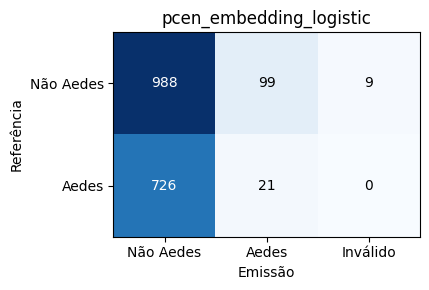

In [2]:
display(pd.read_json(O/'validation_search.json')[['name','validation_precision','validation_recall','validation_macro_f1','validation_minimum_recall','cut']])
display(metrics[metrics.scope.eq('all_fresh')][['model','selected','known_windows','aedes_precision','aedes_recall','aedes_f1','macro_f1','specificity','accuracy']])
display(metrics[metrics.selected & metrics.scope.str.startswith('taxon:')])
r=metrics[metrics.selected & metrics.scope.eq('all_fresh')].iloc[0]
a=np.array(json.loads(r.confusion))
fig,ax=plt.subplots(figsize=(6,3));ax.imshow(a,cmap='Blues')
for (i,j),v in np.ndenumerate(a):ax.text(j,i,str(v),ha='center',va='center',color='white' if v>a.max()/2 else 'black')
ax.set_xticks([0,1,2],['Não Aedes','Aedes','Inválido']);ax.set_yticks([0,1],['Não Aedes','Aedes'])
ax.set(xlabel='Emissão',ylabel='Referência',title=selected);fig.tight_layout()
assets=ROOT/'reports/assets';assets.mkdir(exist_ok=True)
fig.savefig(assets/'aedes_adaptation_confusion.png',dpi=200)
plt.show()

## Curvas precisão–sensibilidade

Scores brutos, sem escolher novo limiar por estas curvas; a matriz operacional mantém os inválidos.

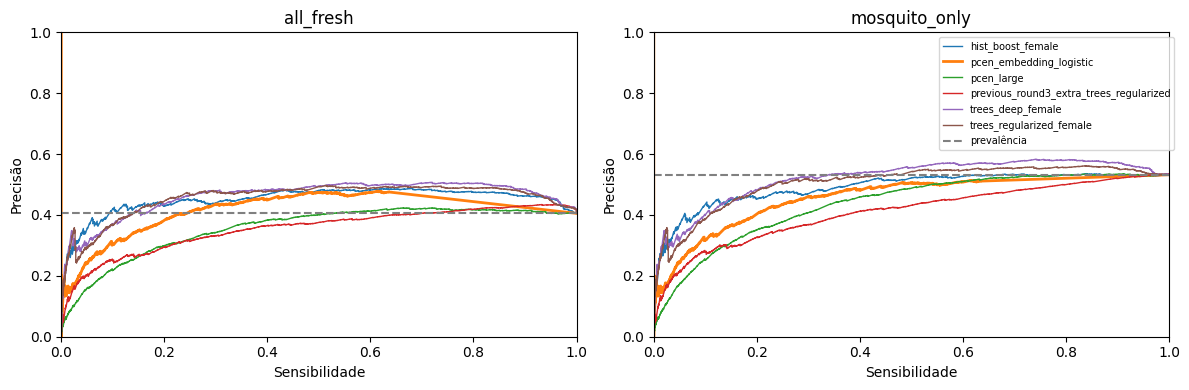

In [3]:
pred=pd.read_csv(O/'fresh_predictions.csv.gz')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,scope in zip(axes,['all_fresh','mosquito_only']):
    sample=pred if scope=='all_fresh' else pred[pred.reference_species.ne('noise')]
    for name,s in sample.groupby('model'):
        precision,recall,_=precision_recall_curve(s.label,s.score)
        ax.plot(recall,precision,label=name,linewidth=2 if name==selected else 1)
    ax.axhline(sample[sample.model.eq(selected)].label.mean(),color='gray',linestyle='--',label='prevalência')
    ax.set(xlabel='Sensibilidade',ylabel='Precisão',title=scope,xlim=(0,1),ylim=(0,1))
axes[1].legend(fontsize=7,bbox_to_anchor=(1.02,1));fig.tight_layout()
fig.savefig(assets/'aedes_adaptation_precision_recall.png',dpi=200,bbox_inches='tight')
plt.show()

## Áudio do Drive e incerteza

Uma gravação positiva conhecida mede sensibilidade, não especificidade/precisão binária.

In [4]:
display(pd.read_csv(O/'private_audio_aggregate_exploratory.csv')[['model','selected','true_positive','known_windows','aedes_recall','invalid','precision_informative_for_binary_detection']])
display(json.loads((O/'fresh_group_bootstrap.json').read_text())[selected])
display(json.loads((O/'paired_improvement_exploratory.json').read_text()))
display(pd.read_csv(O/'stage_explanations.csv').query('model==@selected'))

,model,selected,true_positive,known_windows,aedes_recall,invalid,precision_informative_for_binary_detection
0,trees_regularized_female,False,46,107,0.429907,2,False
1,trees_deep_female,False,55,107,0.514019,2,False
2,hist_boost_female,False,14,107,0.130841,2,False
3,pcen_embedding_logistic,True,0,107,0.000000,2,False
4,pcen_large,False,39,107,0.364486,2,False
5,previous_round3_extra_trees_regularized,False,77,107,0.719626,2,False


{'all_fresh': {'method': '2000 bootstrap replicates, original recording groups stratified by source; CDMSC file identity only, not independent individuals.',
  'groups': 151,
  'metrics': {'aedes_precision': {'lower95': 0.06756377163680535,
    'upper95': 0.35528962492437977},
   'aedes_recall': {'lower95': 0.012235732533259857,
    'upper95': 0.04636874813972753},
   'aedes_f1': {'lower95': 0.021052016724053123,
    'upper95': 0.07895447652745305},
   'specificity': {'lower95': 0.8474358251100839,
    'upper95': 0.946969923765934},
   'macro_f1': {'lower95': 0.3345219776713021, 'upper95': 0.4133677529735711},
   'balanced_accuracy': {'lower95': 0.4343571842526603,
    'upper95': 0.4895935654831529}}},
 'mosquito_only': {'method': '2000 bootstrap replicates, original recording groups stratified by source; CDMSC file identity only, not independent individuals.',
  'groups': 74,
  'metrics': {'aedes_precision': {'lower95': 0.06973894208846329,
    'upper95': 0.3492111302352266},
   'aede

{'new_model': 'pcen_embedding_logistic',
 'previous_model': 'previous_round3_extra_trees_regularized',
 'method': 'Paired identical recording-group bootstrap draws, stratified by source; exploratory, individual identities unknown.',
 'differences': {'all_fresh': {'aedes_precision': {'change': -0.1989754098360656,
    'lower95': -0.31571160454482894,
    'upper95': -0.04719083823923249},
   'aedes_recall': {'change': -0.4605087014725569,
    'lower95': -0.5441415536318556,
    'upper95': -0.3841227636928096},
   'aedes_f1': {'change': -0.3752367219804517,
    'lower95': -0.45383031574041444,
    'upper95': -0.2840854429367923},
   'specificity': {'change': 0.4671532846715328,
    'lower95': 0.386674655012417,
    'upper95': 0.53791617520245},
   'macro_f1': {'change': -0.07961980341875102,
    'lower95': -0.1561049863612203,
    'upper95': -0.0023469655289694888},
   'balanced_accuracy': {'change': 0.0033222915994879365,
    'lower95': -0.053461544144503624,
    'upper95': 0.05468269355

,model,reference_species,presence_stage_score,conditional_species_score,score
15,pcen_embedding_logistic,Aedes aegypti,0.999879,7.882410e-06,0.087908
16,pcen_embedding_logistic,Aedes albopictus,0.999991,4.541432e-07,0.050424
17,pcen_embedding_logistic,Anopheles arabiensis,0.999992,4.550517e-06,0.076704
18,pcen_embedding_logistic,Anopheles coustani,0.999356,5.007316e-06,0.086203
19,pcen_embedding_logistic,Anopheles funestus sl,0.999999,2.361214e-07,0.050424
20,pcen_embedding_logistic,Anopheles funestus ss,0.999971,4.048099e-01,0.865936
21,pcen_embedding_logistic,Anopheles harrisoni,0.999900,2.466404e-06,0.068320
22,pcen_embedding_logistic,Anopheles maculipalpis,0.999895,1.606819e-05,0.122580
23,pcen_embedding_logistic,Anopheles minimus,0.678146,1.235447e-06,0.058054
24,pcen_embedding_logistic,Anopheles squamosus,0.999856,3.640071e-02,0.673409


| Candidato | Precisão validação | Recall validação | Macro-F1 validação | Menor recall por fonte/classe | Limiar final |
| --- | --- | --- | --- | --- | --- |
| trees_regularized_female | 25.7% | 60.2% | 65.6% | 57.3% | 0.6764 |
| trees_deep_female | 25.2% | 63.9% | 65.5% | 62.0% | 0.6569 |
| hist_boost_female | 35.8% | 59.3% | 70.7% | 55.8% | 0.7830 |
| pcen_embedding_logistic | 41.3% | 71.8% | 74.8% | 67.5% | 0.7789 |

Congelamento: **2026-10-01T22:31:17.742296+00:00**. Seleção do novo teste: **2026-10-01T22:32:49.948712+00:00**. O vencedor maximiza o mínimo de precisão, sensibilidade e recalls por fonte/classe na validação, com pequeno termo de macro-F1. Calibração e escolha do limiar usam apenas a partição de calibração. Os modelos e pesos anteriores permaneceram idênticos por SHA-256.

## Outro teste realmente novo após o congelamento

Foram adquiridos **168 arquivos**, dos quais 151 foram avaliados após a regra conservadora de exclusão de colisões de conteúdo/PCM. Nenhum grupo de aquisição ou arquivo exato coincide com o teste anterior. Não substituímos gravações depois de observar resultados.

Aedes positivos e negativos Aedes albopictus/Culex/Anopheles vêm do mesmo domínio acústico CD-MSC D3. Incluímos ainda novos grupos HumBug e fontes ESC-50 do fold 5 não utilizadas anteriormente. Não usamos o domínio D5 óptico. Fontes: [CD-MSC 2026](https://zenodo.org/records/19095788), [HumBugDB](https://zenodo.org/records/4904800) e [ESC-50](https://github.com/karolpiczak/ESC-50).

**Limites importantes:** identidade dos indivíduos/sessões CD-MSC indisponível; novidade por arquivo não comprova uma campanha ou indivíduo independente. HumBug adiciona negativos novos, sem positivos novos da mesma fonte. O rótulo público é do arquivo, sem anotação de presença de batimento em cada janela. Os resultados são concordância com essa referência, não identificação entomológica de cada som. Janelas de um arquivo são correlacionadas.

O campo `duplicate_file` da auditoria marca qualquer colisão de janela PCM quantizada, não necessariamente duplicação do arquivo original. Na rodada anterior, 16 exclusões ESC-50 foram explicadas por 37 janelas silenciosas/constantes iguais; a regra conservadora foi mantida. Nesta rodada, a lista de exclusões é preservada no JSON de decisão, sem substituição por score.


| Fonte | Arquivos selecionados | Segundos |
| --- | --- | --- |
| CDMSC2026_D3 | 48 | 968.3 |
| ESC50_noise | 91 | 455.0 |
| HumBug_noise | 3 | 69.6 |
| HumBug_other_mosquito | 26 | 452.2 |

## Comparação no mesmo teste novo

Somente os quatro candidatos da adaptação participaram da escolha na validação. `pcen_large` é a rede previamente escolhida na rodada anterior e `previous_round3_extra_trees_regularized` é o modelo escolhido na rodada 3: ambos são referências preservadas. Não promovemos um vencedor retrospectivamente pelo teste.

| Modelo | Escolhido antes do teste | Precisão | Recall Aedes | F1 Aedes | Macro-F1 | Especificidade | Acurácia |
| --- | --- | --- | --- | --- | --- | --- | --- |
| hist_boost_female | não | 34.6% | 4.8% | 8.5% | 40.3% | 93.0% | 57.2% |
| pcen_embedding_logistic | sim | 17.5% | 2.8% | 4.8% | 37.6% | 90.1% | 54.7% |
| pcen_large | não | 15.9% | 5.2% | 7.9% | 36.7% | 80.3% | 49.9% |
| previous_round3_extra_trees_regularized | não | 37.4% | 48.9% | 42.4% | 45.5% | 43.4% | 45.6% |
| trees_deep_female | não | 37.2% | 9.9% | 15.6% | 43.0% | 87.8% | 56.2% |
| trees_regularized_female | não | 35.9% | 8.8% | 14.2% | 42.4% | 88.4% | 56.2% |

Neste teste, responder sempre ‘não Aedes’ teria **59.5% de acurácia e zero sensibilidade**. Isso demonstra por que uma taxa geral perto de 60% não torna o detector confiável. A ROC-AUC dos scores brutos do escolhido foi 0.553, com average precision 0.401; a prevalência observada de Aedes é 40.5%. Esses diagnósticos também não mostram separação forte. Não escolhemos um novo limiar pelas curvas do teste.

## Resultado por condição e táxon

| Condição | Janelas | Precisão binária | Recall Aedes | Especificidade | Falsos positivos | Macro-F1 |
| --- | --- | --- | --- | --- | --- | --- |
| all_fresh | 1843 | 17.5% | 2.8% | 90.1% | 9.0% | 37.6% |
| mosquito_only | 1404 | 17.6% | 2.8% | 85.1% | 14.9% | 31.2% |
| CDMSC2026_D3 | 961 | 61.8% | 2.8% | 93.9% | 6.1% | 20.3% |
| ESC50_noise | 370 | só uma classe | — | 97.3% | 0.3% | — |
| HumBug_noise | 69 | só uma classe | — | 100.0% | 0.0% | — |
| HumBug_other_mosquito | 443 | só uma classe | — | 80.8% | 19.2% | — |

| Referência | Grupos/arquivos | Janelas | Aedes emitido | Não Aedes emitido | Inválidos | Acerto relevante |
| --- | --- | --- | --- | --- | --- | --- |
| Aedes aegypti | 24 | 747 | 21 | 726 | 0 | 2.8% |
| Aedes albopictus | 6 | 178 | 1 | 177 | 0 | 99.4% |
| Anopheles arabiensis | 3 | 6 | 2 | 4 | 0 | 66.7% |
| Anopheles coustani | 3 | 51 | 2 | 49 | 0 | 96.1% |
| Anopheles funestus sl | 3 | 50 | 1 | 49 | 0 | 98.0% |
| Anopheles funestus ss | 3 | 68 | 41 | 27 | 0 | 39.7% |
| Anopheles harrisoni | 2 | 8 | 0 | 8 | 0 | 100.0% |
| Anopheles maculipalpis | 3 | 91 | 0 | 91 | 0 | 100.0% |
| Anopheles minimus | 6 | 12 | 0 | 12 | 0 | 100.0% |
| Anopheles squamosus | 3 | 55 | 21 | 34 | 0 | 61.8% |
| Anopheles stephensi | 6 | 12 | 0 | 12 | 0 | 100.0% |
| Culex pipiens | 6 | 12 | 12 | 0 | 0 | 0.0% |
| Culex pipiens complex | 3 | 100 | 18 | 82 | 0 | 82.0% |
| Mansonia uniformis | 3 | 14 | 0 | 14 | 0 | 100.0% |
| noise | 77 | 439 | 1 | 429 | 9 | 97.7% |

Esse detector só responde Aedes/não Aedes. A tabela por táxon mede rejeição dos negativos conhecidos; não demonstra identificação multiclasse. Complexos taxonômicos permanecem incompletamente identificados.

## Matriz de confusão operacional

| Referência | Não Aedes | Aedes | Inválido |
| --- | --- | --- | --- |
| Não Aedes | 988 | 99 | 9 |
| Aedes | 726 | 21 | 0 |

## Incerteza e melhora comparada

Intervalos de 95% com 2.000 reamostragens de gravações/arquivos inteiros, estratificados por fonte; CD-MSC não fornece identidade biológica. Não tratar janelas como amostras independentes.

| Condição | Métrica | IC 95% |
| --- | --- | --- |
| all_fresh | aedes_precision | 6.8%–35.5% |
| all_fresh | aedes_recall | 1.2%–4.6% |
| all_fresh | aedes_f1 | 2.1%–7.9% |
| all_fresh | specificity | 84.7%–94.7% |
| all_fresh | macro_f1 | 33.5%–41.3% |
| all_fresh | balanced_accuracy | 43.4%–49.0% |
| mosquito_only | aedes_precision | 7.0%–34.9% |
| mosquito_only | aedes_recall | 1.2%–4.6% |
| mosquito_only | aedes_f1 | 2.1%–7.8% |
| mosquito_only | specificity | 75.4%–92.5% |
| mosquito_only | macro_f1 | 24.8%–36.9% |
| mosquito_only | balanced_accuracy | 39.0%–47.7% |
| CDMSC2026_D3 | aedes_precision | 35.0%–84.6% |
| CDMSC2026_D3 | aedes_recall | 1.2%–4.6% |
| CDMSC2026_D3 | aedes_f1 | 2.4%–8.7% |
| CDMSC2026_D3 | specificity | 83.5%–98.0% |
| CDMSC2026_D3 | macro_f1 | 10.5%–29.4% |
| CDMSC2026_D3 | balanced_accuracy | 43.0%–50.6% |

A comparação pareada usa os mesmos arquivos e os mesmos sorteios de grupos: novo detector menos ExtraTrees escolhido na rodada 3. Diferenças são exploratórias, condicionais a essa amostra. Ganho parcial não demonstra confiabilidade geral.

| Condição | Métrica | Mudança em pontos percentuais | IC 95% da mudança |
| --- | --- | --- | --- |
| all_fresh | aedes_precision | -19.9 | -31.6 a -4.7 |
| all_fresh | aedes_recall | -46.1 | -54.4 a -38.4 |
| all_fresh | aedes_f1 | -37.5 | -45.4 a -28.4 |
| all_fresh | specificity | +46.7 | +38.7 a +53.8 |
| all_fresh | macro_f1 | -8.0 | -15.6 a -0.2 |
| all_fresh | balanced_accuracy | +0.3 | -5.3 a +5.5 |
| mosquito_only | aedes_precision | -25.0 | -36.6 a -9.1 |
| mosquito_only | aedes_recall | -46.1 | -54.4 a -38.4 |
| mosquito_only | aedes_f1 | -40.7 | -49.1 a -31.2 |
| mosquito_only | specificity | +59.7 | +49.3 a +68.2 |
| mosquito_only | macro_f1 | -5.4 | -14.7 a +3.9 |
| mosquito_only | balanced_accuracy | +6.8 | +0.1 a +12.7 |
| CDMSC2026_D3 | aedes_precision | -6.8 | -34.2 a +18.0 |
| CDMSC2026_D3 | aedes_recall | -46.1 | -54.4 a -38.4 |
| CDMSC2026_D3 | aedes_f1 | -51.7 | -59.8 a -41.8 |
| CDMSC2026_D3 | specificity | +72.0 | +60.0 a +77.2 |
| CDMSC2026_D3 | macro_f1 | -15.5 | -24.7 a -5.2 |
| CDMSC2026_D3 | balanced_accuracy | +13.0 | +5.7 a +17.6 |

## Áudio privado do Drive

Referência do usuário: Aedes em todo o enxame, caixa de vidro e Nano 33 BLE Sense. São 107 janelas de uma gravação conhecida, com duas inválidas no denominador. Não é teste cego e só mede sensibilidade nesse áudio. Precisão aparente de 100% em um arquivo só de positivos não comprova precisão binária. A gravação não entrou no treino e não será publicada.

| Modelo | Selecionado | Aedes detectados /107 | Sensibilidade nesse áudio |
| --- | --- | --- | --- |
| trees_regularized_female | não | 46/107 | 43.0% |
| trees_deep_female | não | 55/107 | 51.4% |
| hist_boost_female | não | 14/107 | 13.1% |
| pcen_embedding_logistic | sim | 0/107 | 0.0% |
| pcen_large | não | 39/107 | 36.4% |
| previous_round3_extra_trees_regularized | não | 77/107 | 72.0% |

## Bases históricas

Diagnóstico de regressões; estas bases já foram examinadas no desenvolvimento. Não substituem o novo teste.

| Fonte | Precisão | Recall Aedes | Especificidade | Macro-F1 |
| --- | --- | --- | --- | --- |
| dryad | 62.1% | 86.1% | 97.5% | 85.3% |
| humbug | 94.0% | 81.8% | 99.1% | 92.9% |
| mosquitosong | só Aedes | 12.5% | — | — |
| ufrgs | 97.8% | 16.2% | 99.3% | 41.9% |

## Explicabilidade

A cada janela pública, registramos score de presença de mosquito, score condicional de Aedes e score final. Isso localiza em qual estágio o alerta falha; não é prova de calibração em campo ou de relevância biológica causal. O encoder combina PCEN, log-Mel e contraste espectral; as features físicas incluem frequência, harmônicos, MFCC e dinâmica, também sensíveis a sexo, temperatura e microfone.

| Referência | Presença, mediana | Aedes condicional, mediana | Final calibrado, mediana |
| --- | --- | --- | --- |
| Aedes aegypti | 1.000 | 0.000 | 0.088 |
| Aedes albopictus | 1.000 | 0.000 | 0.050 |
| Anopheles arabiensis | 1.000 | 0.000 | 0.077 |
| Anopheles coustani | 0.999 | 0.000 | 0.086 |
| Anopheles funestus sl | 1.000 | 0.000 | 0.050 |
| Anopheles funestus ss | 1.000 | 0.405 | 0.866 |
| Anopheles harrisoni | 1.000 | 0.000 | 0.068 |
| Anopheles maculipalpis | 1.000 | 0.000 | 0.123 |
| Anopheles minimus | 0.678 | 0.000 | 0.058 |
| Anopheles squamosus | 1.000 | 0.036 | 0.673 |
| Anopheles stephensi | 0.999 | 0.000 | 0.086 |
| Culex pipiens | 1.000 | 0.955 | 0.958 |
| Culex pipiens complex | 1.000 | 0.000 | 0.295 |
| Mansonia uniformis | 0.998 | 0.000 | 0.119 |
| noise | 0.000 | 0.000 | 0.050 |

A importância por impureza das árvores está em `classical_feature_importance_exploratory.csv`; é sensível a correlação e não explica causalmente a rede. Não afirmamos que um harmônico ou feature identifique exclusivamente Aedes.

## Decisão

Ainda não confiável: não atingiu os mínimos definidos antes do novo teste.

- all_fresh: aedes_precision below .60
- all_fresh: aedes_precision lower95 below .60
- all_fresh: aedes_recall below .60
- all_fresh: aedes_recall lower95 below .60
- all_fresh: macro_f1 below .60
- all_fresh: macro_f1 lower95 below .60
- mosquito_only: aedes_precision below .60
- mosquito_only: aedes_precision lower95 below .60
- mosquito_only: aedes_recall below .60
- mosquito_only: aedes_recall lower95 below .60
- mosquito_only: macro_f1 below .60
- mosquito_only: macro_f1 lower95 below .60
- CDMSC2026_D3: aedes_precision lower95 below .60
- CDMSC2026_D3: aedes_recall below .60
- CDMSC2026_D3: aedes_recall lower95 below .60
- CDMSC2026_D3: macro_f1 below .60
- CDMSC2026_D3: macro_f1 lower95 below .60
- taxon:Aedes aegypti: aedes_recall below .60
- taxon:Anopheles funestus ss: specificity below .60
- taxon:Culex pipiens: specificity below .60

Não podemos garantir que repetir treinamentos nos mesmos corpora produza um detector confiável. Escolher por testes já vistos apenas aumenta o risco de memorizar suas condições. São necessárias novas gravações com identidade/sessão conhecidas, Aedes e negativos confirmados no mesmo aparelho e caixa, incluindo Aedes albopictus e Culex, ruídos, sexos e temperaturas variados. Esses dados devem ser separados por sessão/indivíduo antes da segmentação.

Nenhum firmware, Arduino ou instalador foi modificado: 26 arquivos históricos foram verificados por SHA-256. A comparação é dos modelos em computador, sem compactação. Não afirmamos superar os estudos: tarefa, protocolos e condições de teste não são os mesmos.

## Artefatos e execução

Este notebook apenas lê resultados e produz gráficos. Para reavaliar os modelos congelados localmente:

```bash
.venv/bin/python evaluate_sex_balanced_reliability.py
.venv/bin/python -m unittest tests.test_sex_balanced_reliability tests.test_reliability tests.test_reproduction tests.test_corrected_validation
.venv/bin/python summarize_sex_balanced_reliability.py
```

Os pesos novos e o cache são locais, ignorados pelo Git. Os JSONs/CSVs de `results/sex_balanced_reliability_2026_10_01/` guardam partições, seleção anterior ao teste, hashes, horários, intervalos e decisão. Uma nova rodada deve usar outro protocolo, diretório e outro teste após congelamento.


## Decisão final: somente leitura

In [5]:
decision

{'completed_utc': '2026-10-01T22:36:25.442420+00:00',
 'selected_model': 'pcen_embedding_logistic',
 'offline_minimum_criteria_passed': False,
 'failure_reasons': ['all_fresh: aedes_precision below .60',
  'all_fresh: aedes_precision lower95 below .60',
  'all_fresh: aedes_recall below .60',
  'all_fresh: aedes_recall lower95 below .60',
  'all_fresh: macro_f1 below .60',
  'all_fresh: macro_f1 lower95 below .60',
  'mosquito_only: aedes_precision below .60',
  'mosquito_only: aedes_precision lower95 below .60',
  'mosquito_only: aedes_recall below .60',
  'mosquito_only: aedes_recall lower95 below .60',
  'mosquito_only: macro_f1 below .60',
  'mosquito_only: macro_f1 lower95 below .60',
  'CDMSC2026_D3: aedes_precision lower95 below .60',
  'CDMSC2026_D3: aedes_recall below .60',
  'CDMSC2026_D3: aedes_recall lower95 below .60',
  'CDMSC2026_D3: macro_f1 below .60',
  'CDMSC2026_D3: macro_f1 lower95 below .60',
  'taxon:Aedes aegypti: aedes_recall below .60',
  'taxon:Anopheles funes